# Cross-Market Decision Analysis — Phase 4 + Phase 5

Decision regret and Diebold–Mariano tests on all five markets of the Lago et al. (2021) benchmark.

**Markets:** NP · PJM · BE · FR · DE
**Models:** DNN Ensemble · LEAR Ensemble
**Predictive distribution (eq. 3.5):** p̂_t + (p_s − p̂_s) for the last 90 days of hours s
**Decision:** bang-bang hedge rule z* = 1{f < M_λ}, where M_λ = (1−λ)E[p] + λCVaR_α[p]
**Regret:** R_t = cost(z*) − cost(z_oracle)
**DM test:** daily mean loss differential, HAC (7 daily lags), two-sided

All helpers live in `decision_utils.py`, shared with the other notebooks.

> **Revision of 14 Oct 2026** (feedback of 13 Oct 2026). (1) The predictive distribution now uses residuals p − p̂, as in eq. 3.5; the previous code used p̂ − p, which mirrored the distribution and put price spikes in the lower tail. (2) The DM test is run on daily means and is two-sided. (3) Gap-factor ratios are removed. (4) The disagreement breakdown covers all five markets at π = 5 %. (5) The tail bias is grouped by forecast decile.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from decision_utils import (WINDOW, ALPHA, PREMIUM, LAMBDAS, MARKET_FILES, FIG_DIR,
                            forward_proxy, compute_regret, decisions, disagreement,
                            dm_test, first_significant, tail_calibration)

FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'Data files found: {all(p.exists() for p in MARKET_FILES.values())}')
print(f'Markets: {list(MARKET_FILES)}')
print(f'λ values: {list(LAMBDAS)}')

Data files found: True
Markets: ['NP', 'PJM', 'BE', 'FR', 'DE']
λ values: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(1.0)]


---
# Section 1 — Phase 4: Decision Regret (all 5 markets)

For each market and each model (DNN Ensemble, LEAR Ensemble), we compute hourly regret across λ ∈ {0, …, 1}.

**Forward proxy:** f = 90-day rolling mean of past realised prices × 1.05.

In [2]:
all_regret = {}   # market -> {'DNN': df, 'LEAR': df}
data = {}         # market -> benchmark forecasts

for market, path in MARKET_FILES.items():
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    data[market] = df
    f_pi = forward_proxy(df['Real price'], WINDOW, PREMIUM)
    all_regret[market] = {
        'DNN':  compute_regret(df, 'DNN Ensemble',  f_pi, WINDOW, ALPHA, LAMBDAS),
        'LEAR': compute_regret(df, 'LEAR Ensemble', f_pi, WINDOW, ALPHA, LAMBDAS),
    }
    print(f'{market}: {len(df)} hours, {len(all_regret[market]["DNN"])} evaluated')

NP: 17472 hours, 15312 evaluated


PJM: 17472 hours, 15312 evaluated


BE: 17472 hours, 15312 evaluated


FR: 17472 hours, 15312 evaluated


DE: 17472 hours, 15312 evaluated


In [3]:
# ── Table 4.6: mean regret by market and model, and gap (LEAR − DNN) ──────
show = [0.0, 0.2, 0.5, 1.0]
rows = []
for market, reg in all_regret.items():
    for model in ['DNN', 'LEAR']:
        m = reg[model].mean()
        rows.append({'Market': market, 'Model': model,
                     **{f'λ={l}': m[f'regret_λ={l:.1f}'] for l in show}})
    gap = reg['LEAR'].mean() - reg['DNN'].mean()
    rows.append({'Market': market, 'Model': 'Gap (LEAR − DNN)',
                 **{f'λ={l}': gap[f'regret_λ={l:.1f}'] for l in show}})

regret_table = pd.DataFrame(rows).set_index(['Market', 'Model'])
print('Mean regret (EUR/MWh; PJM in USD/MWh), π = 5 %. Positive gap = DNN has lower regret.\n')
print(regret_table.round(4).to_string())

Mean regret (EUR/MWh; PJM in USD/MWh), π = 5 %. Positive gap = DNN has lower regret.

                          λ=0.0   λ=0.2   λ=0.5   λ=1.0
Market Model                                           
NP     DNN               0.0907  0.1581  0.3985  0.9880
       LEAR              0.0962  0.1591  0.4054  1.0261
       Gap (LEAR − DNN)  0.0056  0.0010  0.0069  0.0380
PJM    DNN               0.2617  0.2744  0.5931  1.9376
       LEAR              0.2845  0.4189  1.0138  2.2854
       Gap (LEAR − DNN)  0.0228  0.1445  0.4207  0.3478
BE     DNN               0.8103  1.4199  3.1548  5.0707
       LEAR              0.8201  1.4878  3.2938  5.2821
       Gap (LEAR − DNN)  0.0099  0.0679  0.1391  0.2114
FR     DNN               0.3468  0.4778  0.8835  1.7034
       LEAR              0.3660  0.4722  0.8811  1.8751
       Gap (LEAR − DNN)  0.0192 -0.0056 -0.0024  0.1717
DE     DNN               0.2106  0.2349  0.4937  1.4261
       LEAR              0.2244  0.2732  0.5925  1.7939
       Gap (LEAR −

## Interpretation — Phase 4: Decision Regret

Regret R_t is the extra cost paid because the hedging decision used a model forecast instead of perfect foresight; lower is better. Gap = mean regret(LEAR) − mean regret(DNN); positive = DNN better.

| Market | Gap λ=0 | Gap λ=0.2 | Gap λ=0.5 | Gap λ=1 |
|---|---|---|---|---|
| NP  | +0.006 | +0.001 | +0.007 | +0.038 |
| PJM | +0.023 | +0.145 | +0.421 | +0.348 |
| BE  | +0.010 | +0.068 | +0.139 | +0.211 |
| FR  | +0.019 | −0.006 | −0.002 | +0.172 |
| DE  | +0.014 | +0.038 | +0.099 | +0.368 |

- At λ = 0 the gap is small in every market (0.006 to 0.023 EUR/MWh).
- At λ = 1 the DNN has the lower regret in all five markets. The gap is largest in DE, PJM and BE and smallest in NP.
- The gap is not monotone in λ everywhere: FR is slightly negative between λ = 0.2 and 0.5, and PJM peaks at λ = 0.7. Whether the gaps are significant is tested in Section 2.

---
# Section 2 — Phase 5: Diebold–Mariano Tests (all 5 markets)

Three DM tests per market, all on the **daily mean** loss differential (the 24 hourly prices of a day are forecast together the day before), with HAC standard errors (7 daily lags), **two-sided**:
1. **MSE** — squared forecast error.
2. **MAE** — absolute forecast error.
3. **Regret** — hourly regret R_t at each λ.

t > 0 means DNN has the lower loss; t < 0 means LEAR has the lower loss.

In [4]:
# ── Table 4.7: accuracy vs decision value ───────────────────────────────
all_dm, summary = {}, []
for market, reg in all_regret.items():
    df = data[market]
    e_dnn  = df['DNN Ensemble']  - df['Real price']
    e_lear = df['LEAR Ensemble'] - df['Real price']
    t_mse, p_mse = dm_test(e_lear ** 2,   e_dnn ** 2,   df.index)
    t_mae, p_mae = dm_test(e_lear.abs(), e_dnn.abs(), df.index)

    rows = []
    for lam in LAMBDAS:
        col = f'regret_λ={lam:.1f}'
        t, p = dm_test(reg['LEAR'][col], reg['DNN'][col], reg['DNN'].index)
        rows.append({'lambda': lam, 't': t, 'p': p,
                     'gap': reg['LEAR'][col].mean() - reg['DNN'][col].mean()})
    dm_df = pd.DataFrame(rows).set_index('lambda')
    all_dm[market] = dm_df

    first_dnn, first_lear = first_significant(dm_df)
    summary.append({'Market': market,
                    'MSE t': t_mse, 'MSE p': p_mse, 'MAE t': t_mae, 'MAE p': p_mae,
                    'First sig. λ (DNN better)': first_dnn if first_dnn is not None else 'none',
                    'First sig. λ (LEAR better)': first_lear if first_lear is not None else 'none',
                    'Gap at λ=1': dm_df.loc[1.0, 'gap'], 'p at λ=1': dm_df.loc[1.0, 'p']})

dm_summary = pd.DataFrame(summary).set_index('Market')
print('DM tests on daily mean loss differentials, HAC 7 lags, two-sided (t > 0: DNN better)\n')
print(dm_summary.round(3).to_string())

print('\nRegret DM t-statistic by λ  (|t| > 1.96 ⇔ p < 0.05)')
print(pd.DataFrame({m: d['t'] for m, d in all_dm.items()}).T.round(1).to_string())
print('\nRegret DM p-value by λ')
print(pd.DataFrame({m: d['p'] for m, d in all_dm.items()}).T.round(3).to_string())

DM tests on daily mean loss differentials, HAC 7 lags, two-sided (t > 0: DNN better)

        MSE t  MSE p  MAE t  MAE p First sig. λ (DNN better) First sig. λ (LEAR better)  Gap at λ=1  p at λ=1
Market                                                                                                       
NP      1.216  0.224  2.037  0.042                      none                       none       0.038     0.102
PJM     0.590  0.555  3.455  0.001                       0.1                       none       0.348     0.001
BE      0.053  0.958  4.031  0.000                       0.2                       none       0.211     0.000
FR     -1.084  0.278  1.624  0.104                       0.7                       none       0.172     0.000
DE      2.885  0.004  2.935  0.003                       0.2                       none       0.368     0.000

Regret DM t-statistic by λ  (|t| > 1.96 ⇔ p < 0.05)
lambda  0.0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  0.9  1.0
NP      0.9  0.9  0.1 -0.3  0

## Interpretation — Phase 5: Diebold–Mariano Tests

| Market | MSE p | MAE p | First λ with DNN significantly better | Gap at λ=1 (p) |
|---|---|---|---|---|
| NP  | 0.224 | 0.042  | none at 5 % | +0.038 (0.102) |
| PJM | 0.555 | 0.001  | 0.1 | +0.348 (0.001) |
| BE  | 0.958 | <0.001 | 0.2 | +0.211 (<0.001) |
| FR  | 0.278 | 0.104  | 0.7 | +0.172 (<0.001) |
| DE  | 0.004 | 0.003  | 0.2 | +0.368 (<0.001) |

- At λ = 0 no regret difference is significant in any market.
- No market shows LEAR significantly better at any λ.
- The onset of a significant regret difference is market-specific: λ = 0.1 in PJM, 0.2 in BE and DE, 0.7 in FR, and never at the 5 % level in NP. In BE the result is borderline between λ = 0.2 and 0.6 (p between 0.04 and 0.13).
- By MAE, the DNN is significantly better in four markets (not FR); by MSE, only in DE. In NP the MAE difference is significant (p = 0.04) while the regret difference is not.

---
# Section 3 — Centrepiece Figures

**Figure 1:** Regret gap (LEAR − DNN) vs λ, and DM t-statistic vs λ, for all markets.
**Figure 2:** Forward premium sensitivity — does the direction of the gap hold at π = 0 %, 5 %, 10 %?

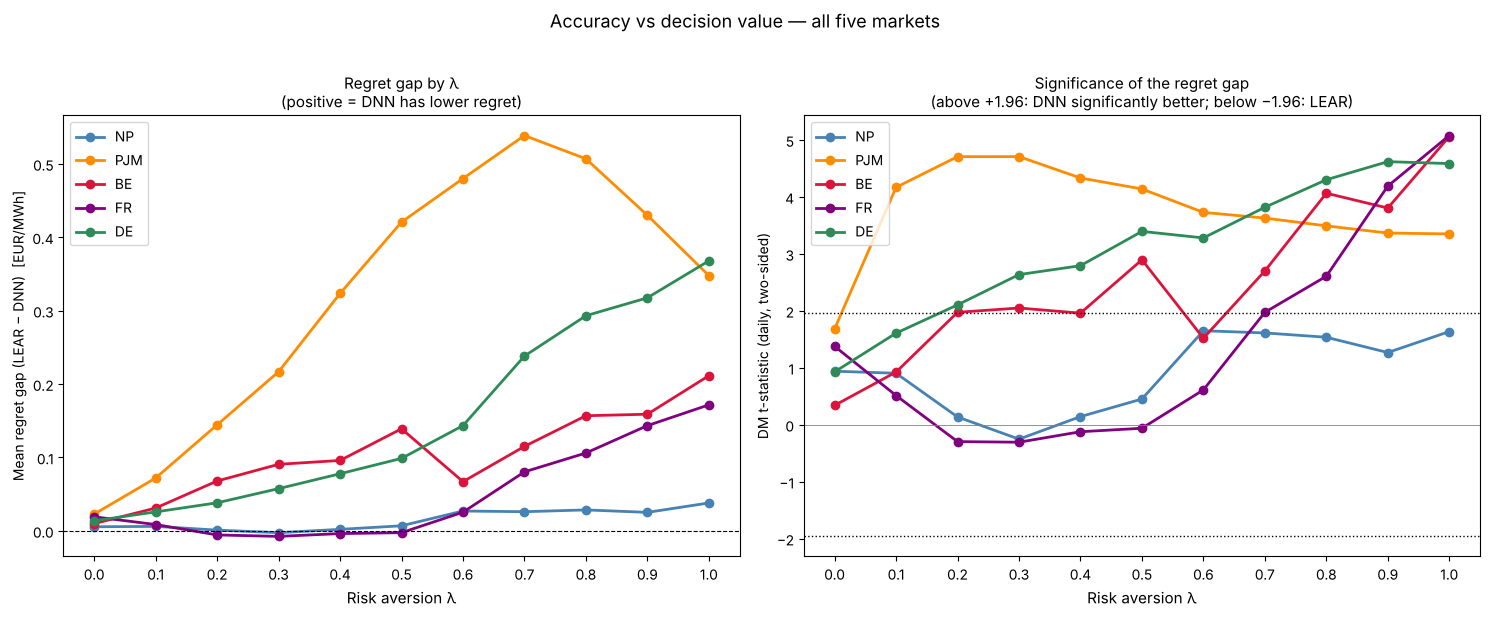

Saved → figures/cross_market_centrepiece.png


In [5]:
# ── Figure 1: centrepiece (2 panels) ────────────────────────────────────
colors = {'NP': 'steelblue', 'PJM': 'darkorange', 'BE': 'crimson', 'FR': 'purple', 'DE': 'seagreen'}
lam_vals = list(LAMBDAS)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]
for market, dm_df in all_dm.items():
    ax.plot(dm_df.index, dm_df['gap'], marker='o', linewidth=2, color=colors[market], label=market)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Risk aversion λ', fontsize=11)
ax.set_ylabel('Mean regret gap (LEAR − DNN)  [EUR/MWh]', fontsize=10)
ax.set_title('Regret gap by λ\n(positive = DNN has lower regret)', fontsize=11)
ax.legend(fontsize=10)
ax.set_xticks(lam_vals)

ax = axes[1]
for market, dm_df in all_dm.items():
    ax.plot(dm_df.index, dm_df['t'], marker='o', linewidth=2, color=colors[market], label=market)
for y in (1.96, -1.96):
    ax.axhline(y, color='black', linewidth=1.0, linestyle=':')
ax.axhline(0, color='grey', linewidth=0.6)
ax.set_xlabel('Risk aversion λ', fontsize=11)
ax.set_ylabel('DM t-statistic (daily, two-sided)', fontsize=10)
ax.set_title('Significance of the regret gap\n(above +1.96: DNN significantly better; below −1.96: LEAR)', fontsize=11)
ax.legend(fontsize=10)
ax.set_xticks(lam_vals)

fig.suptitle('Accuracy vs decision value — all five markets', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'cross_market_centrepiece.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → figures/cross_market_centrepiece.png')

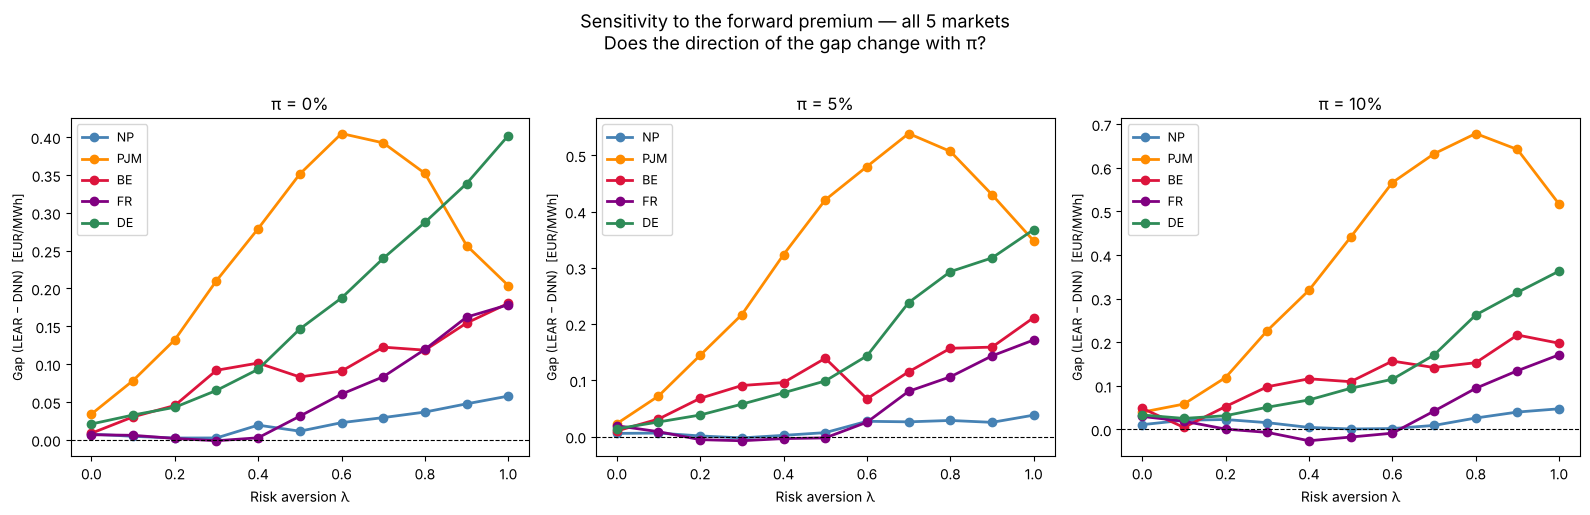

Gap (LEAR − DNN) at λ = 1 by forward premium:
      π=0%   π=5%  π=10%
BE   0.180  0.211  0.198
DE   0.402  0.368  0.363
FR   0.179  0.172  0.171
NP   0.058  0.038  0.047
PJM  0.204  0.348  0.516


In [6]:
# ── Figure 2: forward premium sensitivity (all markets) ──────────────────
premiums = [0.00, 0.05, 0.10]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
gap_at_1 = {}

for ax, pi in zip(axes, premiums):
    for market, df in data.items():
        f_pi = forward_proxy(df['Real price'], WINDOW, pi)
        gap = (compute_regret(df, 'LEAR Ensemble', f_pi).mean()
               - compute_regret(df, 'DNN Ensemble', f_pi).mean())
        gap_at_1[(market, f'π={int(pi * 100)}%')] = gap.iloc[-1]
        ax.plot(lam_vals, gap.values, marker='o', linewidth=2, color=colors[market], label=market)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'π = {int(pi * 100)}%', fontsize=12)
    ax.set_xlabel('Risk aversion λ', fontsize=10)
    ax.set_ylabel('Gap (LEAR − DNN)  [EUR/MWh]', fontsize=9)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.legend(fontsize=9)

fig.suptitle('Sensitivity to the forward premium — all 5 markets\n'
             'Does the direction of the gap change with π?', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'cross_market_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

print('Gap (LEAR − DNN) at λ = 1 by forward premium:')
print(pd.Series(gap_at_1).unstack()[['π=0%', 'π=5%', 'π=10%']].round(3).to_string())

---
# Section 4 — What decides which model wins?

Two diagnostics, on all five markets:
1. **Tail bias** — signed error in the top decile, grouped by **forecast** (what the buyer sees when deciding) and, for comparison, by **realised price** (which selects the hours with the largest positive shocks).
2. **Disagreement breakdown** — in hours where the two models make different hedging decisions at λ = 1, who does the oracle side with?

Mean signed error (forecast − actual) in the top decile, evaluation hours [EUR/MWh]

              Bias, top forecast decile  Bias, top realised-price decile
Market Model                                                            
NP     DNN                        -0.98                            -2.72
       LEAR                       -0.56                            -2.49
PJM    DNN                         0.86                            -2.99
       LEAR                       -2.27                            -6.43
BE     DNN                        -8.43                           -18.78
       LEAR                       -6.75                           -18.27
FR     DNN                        -4.10                            -6.85
       LEAR                       -2.67                            -5.32
DE     DNN                        -1.64                            -4.16
       LEAR                       -3.38                            -5.84


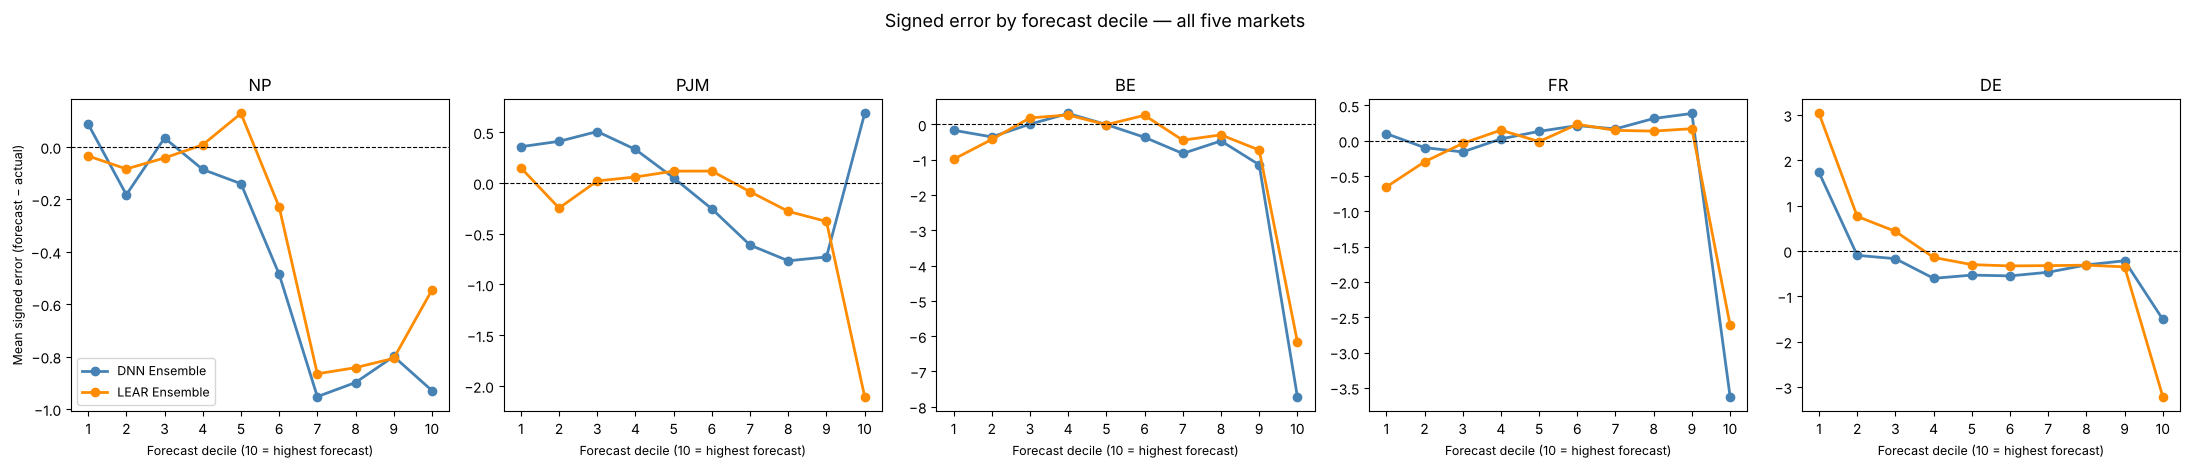

In [7]:
# ── Check 1: tail bias by forecast decile vs by realised-price decile ────
rows = []
for market, df in data.items():
    for model in ['DNN Ensemble', 'LEAR Ensemble']:
        c = tail_calibration(df, model)
        rows.append({'Market': market, 'Model': model.split()[0],
                     'Bias, top forecast decile': c['bias_top_forecast'],
                     'Bias, top realised-price decile': c['bias_top_realised']})
bias_table = pd.DataFrame(rows).set_index(['Market', 'Model'])
print('Mean signed error (forecast − actual) in the top decile, evaluation hours [EUR/MWh]\n')
print(bias_table.round(2).to_string())

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
x = list(range(1, 11))
for ax, (market, df) in zip(axes, data.items()):
    for model, color in [('DNN Ensemble', 'steelblue'), ('LEAR Ensemble', 'darkorange')]:
        dec = pd.qcut(df[model], 10, labels=False) + 1          # decile of the FORECAST
        bias = [(df[model] - df['Real price'])[dec == d].mean() for d in x]
        ax.plot(x, bias, marker='o', color=color, linewidth=2, label=model)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(market, fontsize=12)
    ax.set_xlabel('Forecast decile (10 = highest forecast)', fontsize=9)
    ax.set_xticks(x)
axes[0].set_ylabel('Mean signed error (forecast − actual)', fontsize=9)
axes[0].legend(fontsize=9)
fig.suptitle('Signed error by forecast decile — all five markets', fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / 'tail_bias_by_forecast_decile.png', dpi=150, bbox_inches='tight')
plt.show()

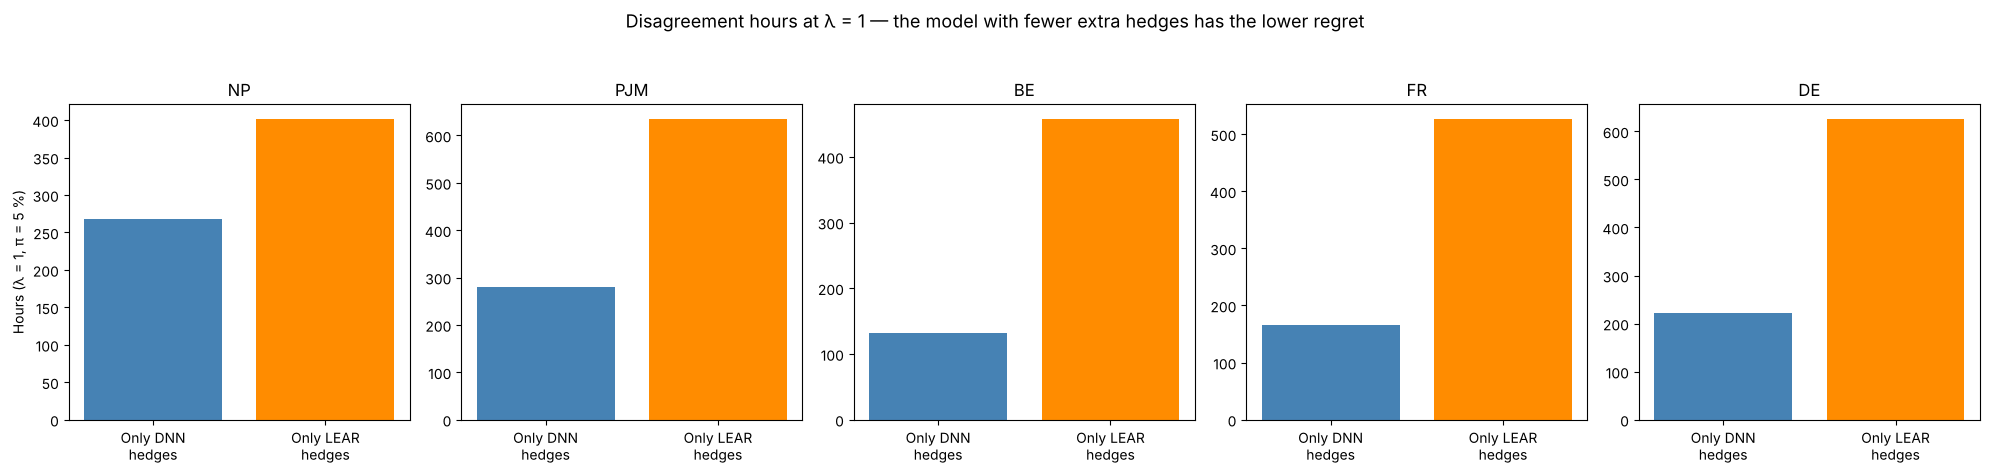

        Only DNN hedges [h]  of which oracle: no hedge  Only LEAR hedges [h]  of which oracle: no hedge  Fewer extra hedges Lower regret at λ=1
Market                                                                                                                                         
NP                      268                      0.996                   401                       0.993                DNN                 DNN
PJM                     281                      0.975                   634                       0.997                DNN                 DNN
BE                      132                      0.970                   457                       0.996                DNN                 DNN
FR                      166                      0.970                   526                       0.985                DNN                 DNN
DE                      222                      0.959                   625                       0.978                DNN             

In [8]:
# ── Check 2: disagreement breakdown at λ = 1, π = 5 % (all markets) ───────
LAM = 1.0
rows = []
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, (market, df) in zip(axes, data.items()):
    f_pi = forward_proxy(df['Real price'], WINDOW, PREMIUM)
    s = disagreement(decisions(df, 'DNN Ensemble', f_pi, LAM),
                     decisions(df, 'LEAR Ensemble', f_pi, LAM))
    gap = all_dm[market].loc[LAM, 'gap']
    rows.append({'Market': market,
                 'Only DNN hedges [h]': s['only_A_hedges'],
                 'of which oracle: no hedge': s['only_A_oracle_no_hedge'],
                 'Only LEAR hedges [h]': s['only_B_hedges'],
                 'of which oracle: no hedge ': s['only_B_oracle_no_hedge'],
                 'Fewer extra hedges': 'DNN' if s['only_A_hedges'] < s['only_B_hedges'] else 'LEAR',
                 'Lower regret at λ=1': 'DNN' if gap > 0 else 'LEAR'})
    ax.bar([0, 1], [s['only_A_hedges'], s['only_B_hedges']], color=['steelblue', 'darkorange'])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Only DNN\nhedges', 'Only LEAR\nhedges'])
    ax.set_title(market, fontsize=12)
axes[0].set_ylabel('Hours (λ = 1, π = 5 %)')
fig.suptitle('Disagreement hours at λ = 1 — the model with fewer extra hedges has the lower regret', fontsize=13, y=1.04)
plt.tight_layout()
plt.savefig(FIG_DIR / 'disagreement_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()

disagree_table = pd.DataFrame(rows).set_index('Market')
print(disagree_table.round(3).to_string())

## Conclusion — what decides which model wins

**Tail bias does not decide it.** Grouped by forecast decile (the hours the buyer sees as expensive when deciding), the top-decile bias is small and its sign varies: LEAR is less biased in NP, BE and FR, the DNN in PJM and DE. Yet the DNN has the lower regret at λ = 1 in all five markets. Grouped by realised price, both models look strongly biased downward (−2.5 to −18.8 EUR/MWh), but this is mostly a selection effect: hours chosen because the price ended high are hours with large positive shocks.

**Hedging decisions do.** In the hours where the two models disagree at λ = 1, the oracle sides with the model that does *not* hedge in 96 to 100 % of cases. The model with lower regret is therefore the one that triggers fewer unnecessary hedges: the DNN in all five markets (for example NP 268 vs 401 hours, PJM 281 vs 634).

This is a decomposition of the regret, not a causal explanation of why one model's CVaR crosses the forward price less often.

---
# Section 5 — Phase 7: Rank Correlation Across All 10 Models

Sections 1-4 compared only the **two ensembles** (DNN Ensemble vs LEAR Ensemble). But the benchmark dataset contains **10 models**:

| Model | Type | Description |
|---|---|---|
| DNN 1 | Neural net | Independent training run 1 |
| DNN 2 | Neural net | Independent training run 2 |
| DNN 3 | Neural net | Independent training run 3 |
| DNN 4 | Neural net | Independent training run 4 |
| DNN Ensemble | Neural net | Average of DNN 1-4 |
| LEAR 56 | Linear | Calibration window = 56 days |
| LEAR 84 | Linear | Calibration window = 84 days |
| LEAR 1092 | Linear | Calibration window = 1092 days |
| LEAR 1456 | Linear | Calibration window = 1456 days |
| LEAR Ensemble | Linear | Average of LEAR 56/84/1092/1456 |

**Question:** If we rank all 10 models by MAE and separately by regret at each λ, how well do the two rankings agree?

**Method:** Spearman rank correlation between MAE ranking and regret ranking.
- ρ ≈ 1 → MAE ranking perfectly predicts regret ranking (accuracy is a good proxy for decision value)
- ρ ≈ 0 → MAE ranking tells you nothing about which model minimises regret

If the thesis claim is correct, ρ should be high near λ=0 and decline as λ increases.

In [9]:
from scipy.stats import spearmanr

MODEL_COLS = [
    'DNN 1', 'DNN 2', 'DNN 3', 'DNN 4', 'DNN Ensemble',
    'LEAR 56', 'LEAR 84', 'LEAR 1092', 'LEAR 1456', 'LEAR Ensemble',
]

# ── Step 1: Compute MAE for all 10 models on all 5 markets ──────────────
mae_all = {}  # market -> Series (index = model name)

for market, path in MARKET_FILES.items():
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    maes = {}
    for col in MODEL_COLS:
        maes[col] = np.abs(df[col] - df['Real price']).mean()
    mae_all[market] = pd.Series(maes)
    print(f'{market} MAE: best = {mae_all[market].idxmin()} ({mae_all[market].min():.3f}), '
          f'worst = {mae_all[market].idxmax()} ({mae_all[market].max():.3f})')

print('\nMAE computed for all 10 models on all 5 markets.')

NP MAE: best = DNN Ensemble (1.683), worst = DNN 2 (2.118)
PJM MAE: best = DNN Ensemble (2.862), worst = LEAR 56 (3.477)
BE MAE: best = DNN Ensemble (5.870), worst = LEAR 56 (6.924)
FR MAE: best = DNN Ensemble (3.866), worst = LEAR 56 (4.681)


DE MAE: best = DNN Ensemble (3.413), worst = LEAR 56 (4.283)

MAE computed for all 10 models on all 5 markets.


In [10]:
# ── Step 2: mean regret for all 10 models (vectorised, about 2 minutes) ──
regret_all = {}  # market -> DataFrame (rows = models, cols = lambdas)
for market, df in data.items():
    f_pi = forward_proxy(df['Real price'], WINDOW, PREMIUM)
    regret_all[market] = pd.DataFrame(
        {col: compute_regret(df, col, f_pi).mean().values for col in MODEL_COLS},
        index=LAMBDAS).T
    print(f'{market}: done')

print('\nMean regret at λ = 0 and λ = 1, all models:')
print(pd.concat({m: r[[0.0, 1.0]] for m, r in regret_all.items()}, axis=1).round(4).to_string())

NP: done


PJM: done


BE: done


FR: done


DE: done

Mean regret at λ = 0 and λ = 1, all models:
                   NP             PJM              BE              FR              DE        
                  0.0     1.0     0.0     1.0     0.0     1.0     0.0     1.0     0.0     1.0
DNN 1          0.1024  1.0070  0.3051  2.3164  0.8603  5.1055  0.4103  1.8671  0.2476  1.8594
DNN 2          0.1381  1.2326  0.2858  2.2900  0.8960  5.2396  0.3801  1.8859  0.2403  1.6618
DNN 3          0.0991  0.9661  0.2987  2.3081  0.9176  5.2512  0.3772  1.8031  0.2415  1.5681
DNN 4          0.1214  1.0759  0.2926  2.1294  0.8519  5.1994  0.3908  1.9005  0.2264  1.5231
DNN Ensemble   0.0907  0.9880  0.2617  1.9376  0.8103  5.0707  0.3468  1.7034  0.2106  1.4261
LEAR 56        0.1356  1.3324  0.3811  2.6363  1.0367  5.6411  0.4682  2.3877  0.3316  2.6343
LEAR 84        0.1233  1.2830  0.3970  2.6276  1.0128  5.5393  0.4745  2.3957  0.3286  2.5182
LEAR 1092      0.1279  0.9786  0.2937  2.3116  0.8706  5.4448  0.4064  2.0911  0.2536  1.7074
LEAR 1

In [11]:
# ── Step 3: Spearman rank correlation (MAE rank vs regret rank) ──────────
corr_table = {}  # market -> {lambda: rho}

print('Spearman rank correlations (MAE rank vs regret rank)')
print('='*70)

for market in MARKET_FILES:
    mae_rank = mae_all[market].rank()
    corrs = {}
    for lam in LAMBDAS:
        regret_rank = regret_all[market][lam].rank()
        rho, pval = spearmanr(mae_rank, regret_rank)
        corrs[lam] = rho
    corr_table[market] = corrs
    
    vals = [f'{corrs[lam]:.3f}' for lam in LAMBDAS]
    print(f'{market}: ' + '  '.join(vals))

# ── Display as a clean DataFrame ─────────────────────────────────────────
print('\n')
corr_df = pd.DataFrame(corr_table).T
corr_df.columns = [f'λ={lam:.1f}' for lam in LAMBDAS]
display_cols = ['λ=0.0', 'λ=0.2', 'λ=0.4', 'λ=0.6', 'λ=0.8', 'λ=1.0']
print(corr_df[display_cols].to_string(float_format='%.2f'))

Spearman rank correlations (MAE rank vs regret rank)
NP: 0.952  0.879  0.830  0.770  0.648  0.442  0.539  0.552  0.370  0.406  0.467
PJM: 0.855  0.552  0.576  0.588  0.588  0.588  0.564  0.503  0.564  0.564  0.903
BE: 0.818  0.867  0.855  0.855  0.879  0.842  0.842  0.891  0.867  0.903  0.842
FR: 0.939  0.952  0.915  0.915  0.855  0.927  0.879  0.915  0.976  0.976  0.915
DE: 0.952  0.915  0.818  0.842  0.733  0.673  0.661  0.636  0.661  0.733  0.758


     λ=0.0  λ=0.2  λ=0.4  λ=0.6  λ=0.8  λ=1.0
NP    0.95   0.83   0.65   0.54   0.37   0.47
PJM   0.85   0.58   0.59   0.56   0.56   0.90
BE    0.82   0.85   0.88   0.84   0.87   0.84
FR    0.94   0.92   0.85   0.88   0.98   0.92
DE    0.95   0.82   0.73   0.66   0.66   0.76


In [12]:
# ── Step 4: Side-by-side rankings (MAE vs Regret) for each market ────────
print('Model rankings: MAE vs Regret at λ=0.0 and λ=1.0')
print('='*70)

for market in MARKET_FILES:
    print(f'\n{market}:')
    rank_df = pd.DataFrame({
        'MAE': mae_all[market].rank().astype(int),
        'Regret λ=0.0': regret_all[market][0.0].rank().astype(int),
        'Regret λ=1.0': regret_all[market][1.0].rank().astype(int),
    })
    print(rank_df.sort_values('MAE').to_string())
    
    # How many models change rank by 3+ positions?
    rank_shift = (rank_df['MAE'] - rank_df['Regret λ=1.0']).abs()
    big_shifts = (rank_shift >= 3).sum()
    print(f'  → {big_shifts}/10 models shift by 3+ rank positions from MAE to Regret@λ=1')

Model rankings: MAE vs Regret at λ=0.0 and λ=1.0

NP:
               MAE  Regret λ=0.0  Regret λ=1.0
DNN Ensemble     1             1             3
DNN 3            2             3             1
LEAR Ensemble    3             2             5
DNN 1            4             4             4
DNN 4            5             5             7
LEAR 84          6             6             9
LEAR 56          7             9            10
LEAR 1456        8             7             6
LEAR 1092        9             8             2
DNN 2           10            10             8
  → 3/10 models shift by 3+ rank positions from MAE to Regret@λ=1

PJM:
               MAE  Regret λ=0.0  Regret λ=1.0
DNN Ensemble     1             1             1
LEAR Ensemble    2             2             3
DNN 4            3             5             2
LEAR 1456        4             4             5
LEAR 1092        5             6             7
DNN 3            6             7             6
DNN 2            7          

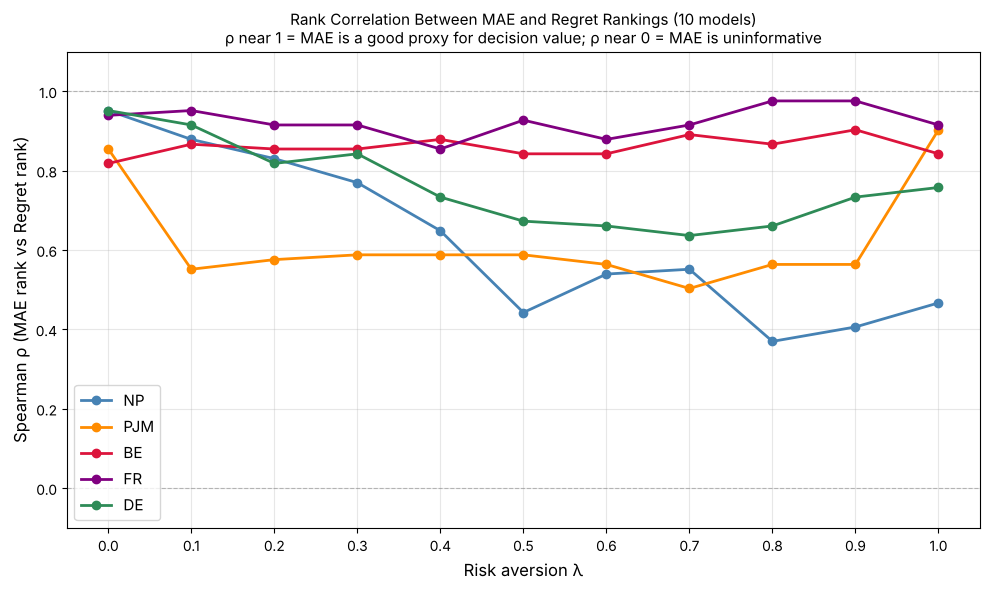

Saved → figures/rank_correlation.png


In [13]:
# ── Step 5: Visualise the correlation decline ────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

for market in MARKET_FILES:
    rhos = [corr_table[market][lam] for lam in LAMBDAS]
    ax.plot(LAMBDAS, rhos, marker='o', linewidth=2, color=colors[market], label=market)

ax.axhline(1.0, color='grey', linewidth=0.8, linestyle='--', alpha=0.5)
ax.axhline(0.0, color='grey', linewidth=0.8, linestyle='--', alpha=0.5)
ax.set_xlabel('Risk aversion λ', fontsize=12)
ax.set_ylabel('Spearman ρ (MAE rank vs Regret rank)', fontsize=12)
ax.set_title('Rank Correlation Between MAE and Regret Rankings (10 models)\n'
             'ρ near 1 = MAE is a good proxy for decision value; ρ near 0 = MAE is uninformative',
             fontsize=11)
ax.set_xticks(list(LAMBDAS))
ax.set_ylim(-0.1, 1.1)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'rank_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → figures/rank_correlation.png')

## Interpretation — Phase 7: Rank Correlation

Spearman ρ between the MAE ranking and the regret ranking of the 10 benchmark models.

| Market | ρ at λ=0 | Lowest ρ (at λ) | ρ at λ=1 |
|---|---|---|---|
| NP  | 0.95 | 0.37 (0.8) | 0.47 |
| PJM | 0.85 | 0.50 (0.7) | 0.90 |
| BE  | 0.82 | 0.82 (0.0) | 0.84 |
| FR  | 0.94 | 0.85 (0.4) | 0.92 |
| DE  | 0.95 | 0.64 (0.7) | 0.76 |

- At λ = 0 the two rankings agree closely in every market (ρ = 0.82 to 0.95).
- As λ grows, agreement falls clearly in NP and DE, and in PJM at intermediate λ (it recovers to 0.90 at λ = 1). In BE and FR it stays high at every λ (ρ ≥ 0.82).
- MAE therefore remains a reasonable guide to decision value in some markets and not in others: the divergence is market-dependent.
- With only 10 models, no significance test is applied to ρ; one swap of two adjacent models moves ρ by about 0.01.

---
# Section 6 — Multiple testing: Holm correction

The regret DM test is run at 11 values of λ in each of 5 markets: 55 tests. At the 5 % level, about one test in twenty rejects by chance even if the two models are equally good.

**Holm (1979)** controls the probability of at least one false rejection in a family of tests: sort the m p-values, multiply the k-th smallest by (m − k + 1), keep the sequence non-decreasing. Two families:
- the 11 tests of one market (the question "does the gap appear in this market, and from which λ?");
- all 55 tests together (the strictest reading).

Holm does not use the strong positive dependence between tests at neighbouring λ, so it is conservative.

In [14]:
from decision_utils import holm

allp = np.concatenate([all_dm[m]['p'].values for m in all_dm])
adj55 = holm(allp).reshape(len(all_dm), -1)
rows = []
for i, (market, dm_df) in enumerate(all_dm.items()):
    dm_df['p_holm11'] = holm(dm_df['p'])
    dm_df['p_holm55'] = adj55[i]
    row = {'Market': market}
    for col, name in [('p', 'unadjusted'), ('p_holm11', 'Holm 11'), ('p_holm55', 'Holm 55')]:
        first_dnn, first_lear = first_significant(dm_df, pcol=col)
        row[f'First λ ({name})'] = first_dnn if first_dnn is not None else 'none'
        row[f'# sig. ({name})'] = int((dm_df[col] < 0.05).sum())
        assert first_lear is None          # LEAR is never significantly better
    rows.append(row)
holm_table = pd.DataFrame(rows).set_index('Market')
print('First λ with DNN significantly lower regret, and number of significant λ (of 11):\n')
print(holm_table.to_string())
print('\np-values by λ: unadjusted / Holm within market / Holm over 55 tests\n')
print(pd.concat({m: d[['p', 'p_holm11', 'p_holm55']] for m, d in all_dm.items()}, axis=1).round(3).to_string())

First λ with DNN significantly lower regret, and number of significant λ (of 11):

       First λ (unadjusted)  # sig. (unadjusted) First λ (Holm 11)  # sig. (Holm 11) First λ (Holm 55)  # sig. (Holm 55)
Market                                                                                                                  
NP                     none                    0              none                 0              none                 0
PJM                     0.1                   10               0.1                10               0.1                10
BE                      0.2                    7               0.5                 5               0.8                 3
FR                      0.7                    4               0.9                 2               0.9                 2
DE                      0.2                    9               0.3                 8               0.5                 6

p-values by λ: unadjusted / Holm within market / Holm over 55 tests



## Interpretation — Holm correction

| Market | First λ, unadjusted | Holm, 11 tests | Holm, 55 tests |
|---|---|---|---|
| NP  | none | none | none |
| PJM | 0.1 | 0.1 | 0.1 |
| BE  | 0.2 | 0.5 | 0.8 |
| FR  | 0.7 | 0.9 | 0.9 |
| DE  | 0.2 | 0.3 | 0.5 |

- PJM is unaffected: the DNN is significantly better at every λ ≥ 0.1, even with 55 tests.
- In BE, DE and FR the onset moves to a higher λ. The borderline BE results at λ = 0.2–0.4 (p ≈ 0.04–0.05) do not survive.
- At λ = 1 the four markets that were significant (PJM, BE, FR, DE) remain significant under both corrections. NP has nothing to correct.
- The qualitative result holds: no significant gap at λ = 0, a significant DNN advantage at high λ in four markets, onset market-specific. The precise onset values are fragile and should be quoted with the correction.

---
# Section 7 — The buyer's own criterion

Regret measures the distance to perfect foresight: every hedge that turns out more expensive than the spot price counts against the model, even when a risk-averse buyer would accept it. The buyer's own objective (thesis eq. 3.2) is

  ρ_λ = (1 − λ) · mean(cost) + λ · CVaR₁₀%(cost),  cost_t = z*_t f_t + (1 − z*_t) p_t,

evaluated here on the costs actually paid over the test period (CVaR = mean of the 10 % most expensive hours). Lower is better.

CVaR is not an average of hourly losses, so the DM test does not apply. The difference ρ_λ(LEAR) − ρ_λ(DNN) is tested with a **paired moving-block bootstrap**: whole days are resampled in blocks of 7 consecutive days, the same draw for both models (2,000 draws).

ρ_λ(LEAR) − ρ_λ(DNN), EUR/MWh (PJM USD/MWh); positive = DNN better for the buyer

lambda    0.0    0.1    0.2    0.3    0.4    0.5    0.6    0.7    0.8    0.9    1.0
NP      0.006  0.009  0.009  0.008  0.017  0.020  0.037  0.024  0.026  0.016  0.024
PJM     0.023  0.050  0.110  0.167  0.242  0.295  0.296  0.277  0.197  0.110  0.043
BE      0.010  0.015  0.061  0.028  0.011  0.019 -0.006  0.021  0.036  0.032  0.000
FR      0.019 -0.007 -0.060 -0.124 -0.182 -0.264 -0.229 -0.139 -0.109 -0.072 -0.043
DE      0.014  0.029  0.055  0.101  0.155  0.170  0.260  0.391  0.351  0.233  0.195

Bootstrap p-value (two-sided):

lambda    0.0    0.1    0.2    0.3    0.4    0.5    0.6    0.7    0.8    0.9    1.0
NP      0.317  0.360  0.508  0.731  0.552  0.552  0.333  0.665  0.725  0.885  0.782
PJM     0.092  0.006  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.002
BE      0.866  0.737  0.064  0.411  0.742  0.535  0.837  0.385  0.001  0.000  1.000
FR      0.208  0.836  0.148  0.047  0.051  0.

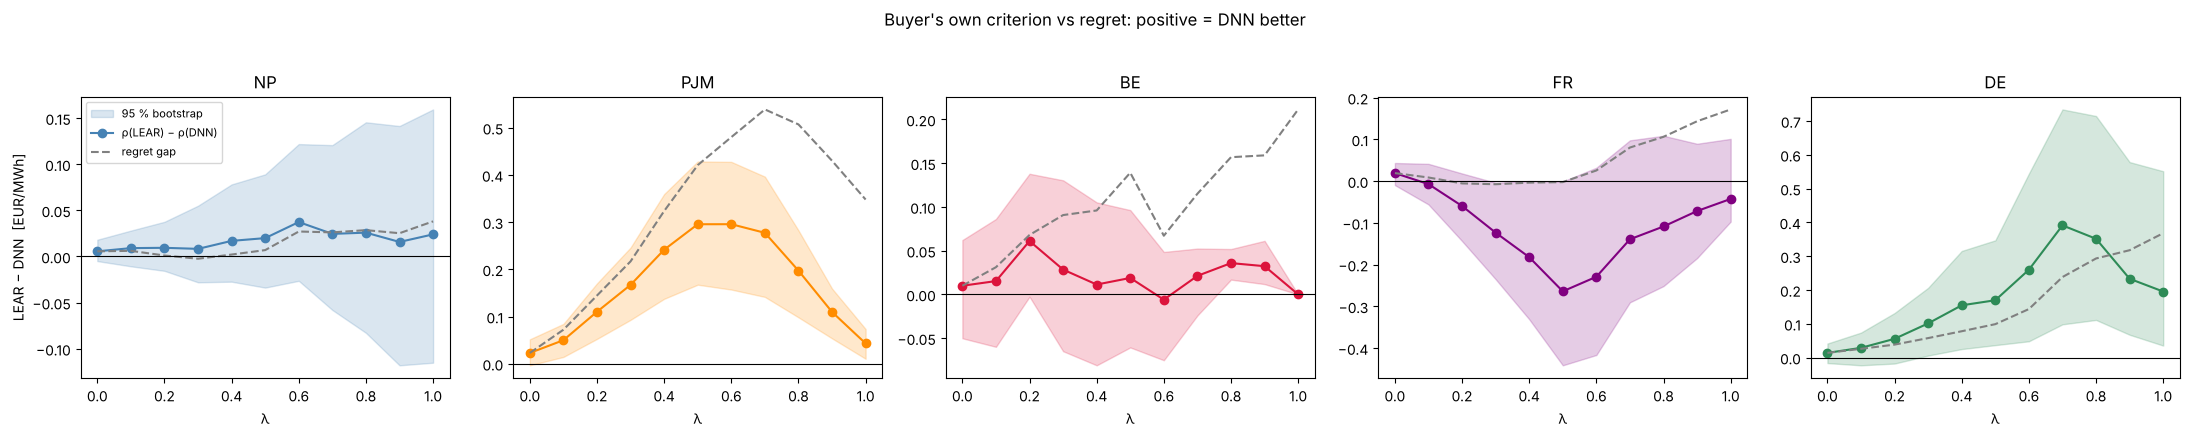

In [15]:
from decision_utils import hedging_costs, buyer_objective, block_bootstrap_diff

buyer = {}
for market, df in data.items():
    f_pi = forward_proxy(df['Real price'], WINDOW, PREMIUM)
    cost = {k: hedging_costs(df, f'{k} Ensemble', f_pi) for k in ('DNN', 'LEAR')}
    res = []
    for lam in LAMBDAS:
        col = f'cost_λ={lam:.1f}'
        d, lo, hi, p = block_bootstrap_diff(cost['LEAR'][col], cost['DNN'][col], cost['DNN'].index, lam)
        res.append({'lambda': lam, 'rho_DNN': buyer_objective(cost['DNN'][col].values, lam),
                    'rho_LEAR': buyer_objective(cost['LEAR'][col].values, lam),
                    'diff': d, 'ci_low': lo, 'ci_high': hi, 'p': p})
    buyer[market] = pd.DataFrame(res).set_index('lambda')

print('ρ_λ(LEAR) − ρ_λ(DNN), EUR/MWh (PJM USD/MWh); positive = DNN better for the buyer\n')
print(pd.concat({m: b['diff'] for m, b in buyer.items()}, axis=1).T.round(3).to_string())
print('\nBootstrap p-value (two-sided):\n')
print(pd.concat({m: b['p'] for m, b in buyer.items()}, axis=1).T.round(3).to_string())

fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, (market, b) in zip(axes, buyer.items()):
    ax.fill_between(b.index, b['ci_low'], b['ci_high'], color=colors[market], alpha=0.2, label='95 % bootstrap')
    ax.plot(b.index, b['diff'], marker='o', color=colors[market], label='ρ(LEAR) − ρ(DNN)')
    reg_gap = all_dm[market]['gap']
    ax.plot(reg_gap.index, reg_gap.values, linestyle='--', color='grey', label='regret gap')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(market)
    ax.set_xlabel('λ')
axes[0].set_ylabel('LEAR − DNN  [EUR/MWh]')
axes[0].legend(fontsize=8)
plt.suptitle("Buyer's own criterion vs regret: positive = DNN better", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / 'buyer_criterion.png', dpi=150, bbox_inches='tight')
plt.show()

## Interpretation — the buyer's own criterion

- **λ = 0:** ρ₀ is the mean cost, which equals mean regret plus a constant shared by both models, so the differences are the regret gaps (+0.006 to +0.023), none significant.
- **PJM and DE:** the DNN gives the buyer a significantly lower objective at most λ (PJM from λ = 0.1, DE from λ = 0.3), as with regret.
- **NP:** the DNN is slightly better at every λ, never significantly.
- **BE:** significant only at λ = 0.8 and 0.9. At λ = 1 the two models pay exactly the same cost in the 10 % most expensive hours: every hour where they disagree is cheaper than that, so a pure-CVaR criterion cannot separate them.
- **FR:** LEAR has the lower objective from λ = 0.1, borderline significant at λ = 0.3 and 0.5 (p ≈ 0.05), not at λ = 1. Regret says the opposite at high λ (DNN better from λ = 0.7).

Regret and the buyer's own criterion agree on direction in four markets and disagree in France. The two measure different things: regret penalises every unnecessary hedge, while ρ_λ rewards hedges that cut the most expensive hours and, at λ = 1, ignores the 90 % cheapest hours. The choice of evaluation metric is itself part of the decision problem.